# S1 SM inversion (Alaska)

Same De Zan coherence/phase-closure soil-moisture inversion as
[`NISAR_SM_alaska.ipynb`](NISAR_SM_alaska.ipynb) (`calc_SM_coherences`/
`invert_sm` from `INSAR4SM-main`, in-situ-driven per-station dry-date
selection, no ERA5) -- but reading `S1_coherence_closure_alaska/`'s CSVs
(from [`S1_coh_phase_closure.ipynb`](S1_coh_phase_closure.ipynb)) instead of
NISAR's GSLC-derived ones. Runs **SoilGrids texture only, both depths**,
exactly like the NISAR notebook:

- **SoilGrids** (`soilgrids_data/alaska/`) -- in-situ ISMN texture is no
  longer used here (dropped in favor of SoilGrids alone).
- **5cm (main) and 20cm (secondary) depth**, the 20cm run reusing the same
  dry-anchor acquisition date as the 5cm run per (station, orbit).

That's 2 variants per (station, orbit): (SoilGrids, 5cm), (SoilGrids, 20cm).

**Differences from `NISAR_SM_alaska.ipynb`, driven by real differences in the
S1 pipeline** (same ones `Checks_alaska_S1.ipynb` documents):
- **VV only, no polarization axis.** These bursts are single-pol VV, so
  `sm_map`/`results_df` here have no `pol` dimension.
- **One coherence CSV per (station, orbit), not one per station.**
  `S1_coherence_closure_alaska/{station}_orbit{orbit}_S1_coherence.csv`
  already is one (station, orbit) group's full pairwise matrix -- no
  `groupby("orbit_num")` needed, unlike the NISAR notebook's single
  per-station file covering every track.
- **C-band, not L-band.** `invert_sm` is called with `freq_GHz=5.405`
  (Sentinel-1's C-band) instead of NISAR's `1.2575` -- this materially
  changes the forward model, not just a label.
- **`local_incidence_angle_deg` comes from `_lv_theta.tif`** (the HyP3

In [1]:
import sys
import os
from pathlib import Path

import pyproj
pyproj.datadir.set_data_dir(os.path.join(sys.prefix, "Library", "share", "proj"))


def require_globals(*names):
    missing = [n for n in names if n not in globals()]
    if missing:
        raise RuntimeError(
            f"Missing {missing} -- run the earlier setup cells first "
            "(the kernel may have been restarted)."
        )


BASE = Path.cwd()
EARSEL_NOTEBOOKS = BASE / "Earsel26_NISAR-main" / "notebooks"
COH_CLOSURE_DIR = BASE / "S1_coherence_closure_alaska"
INSITU_DIR = EARSEL_NOTEBOOKS / "ismn_data" / "alaska" / "station_data"
SOILGRIDS_DIR = BASE / "soilgrids_data" / "alaska"

if str(BASE / "INSAR4SM-main") not in sys.path:
    sys.path.append(str(BASE / "INSAR4SM-main"))

import numpy as np
import pandas as pd
import rasterio
from insar4sm.coh_funcs import calc_SM_coherences
from insar4sm.inversion import invert_sm


C:\Users\geoka\miniconda3\envs\nisar-era5\Lib\site-packages\pyproj\network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


## 1. Station list

In [2]:
require_globals("EARSEL_NOTEBOOKS")

import json

stations_path = EARSEL_NOTEBOOKS / "ismn_data" / "alaska" / "stations.geojson"
with open(stations_path) as f:
    stations_geojson = json.load(f)
stations = {
    feat["properties"]["station_val"]: (
        feat["geometry"]["coordinates"][1],  # lat
        feat["geometry"]["coordinates"][0],  # lon
    )
    for feat in stations_geojson["features"]
}
print(f"Loaded {len(stations)} stations")


Loaded 20 stations


## 2. In-situ SM reader and a generic bracket-interpolator

Identical to `NISAR_SM_alaska.ipynb` -- irregular real sensor timestamps
(SNOTEL/USCRN, not a fixed hourly grid), so `interp_insitu_at` brackets the
nearest real readings and caps how far apart they're allowed to be, rather
than assuming a fixed grid.

In [3]:
require_globals("INSITU_DIR")

MAX_GAP_HOURS = 6
DEPTH_MAIN = 0.05
DEPTH_SECONDARY = 0.20

def read_insitu(station, depth):
    path = INSITU_DIR / f"{station}_ts_{depth:.2f}.csv"
    if not path.exists():
        return None
    df = pd.read_csv(path, index_col=0, parse_dates=True)
    return df.iloc[:, 0].sort_index()  # single sm_<depth> column, whatever it's named


def interp_insitu_at(series, ts):
    before = series.loc[:ts]
    after = series.loc[ts:]
    if before.empty or after.empty:
        return np.nan
    t0, v0 = before.index[-1], before.iloc[-1]
    t1, v1 = after.index[0], after.iloc[0]
    if t0 == t1:
        return float(v0)
    gap_hours = (t1 - t0).total_seconds() / 3600.0
    if gap_hours > MAX_GAP_HOURS:
        return np.nan
    frac = (ts - t0).total_seconds() / (t1 - t0).total_seconds()
    return float(v0 + frac * (v1 - v0))

## 3. Soil texture: SoilGrids

Identical to `NISAR_SM_alaska.ipynb` -- same `soilgrids_data` directory,
same two-tile SoilGrids fallback, same depth-layer convention. In-situ ISMN
texture is no longer used.

In [4]:
require_globals("SOILGRIDS_DIR", "stations")


def sample_soilgrids(band_stem, lon, lat):
    for suffix in ("", "_ii"):
        path = SOILGRIDS_DIR / f"{band_stem}{suffix}.tif"
        if not path.exists():
            continue
        with rasterio.open(path) as src:
            row, col = src.index(lon, lat)
            if not (0 <= row < src.height and 0 <= col < src.width):
                continue
            val = float(src.read(1)[row, col])
            if 0 < val <= 1000:  # plausible g/kg range; SoilGrids has no explicit nodata sentinel here
                return val / 10.0  # g/kg -> %
    return None


def porosity_from_texture(sand_pct, clay_pct):
    return 100 * (0.332 - 7.251e-4 * sand_pct + 0.1276 * np.log10(clay_pct))


TEXTURE_LAYERS = {DEPTH_MAIN: "0to5cm", DEPTH_SECONDARY: "15to30cm"}

texture_soilgrids = {}
for station, (lat, lon) in stations.items():
    sg_by_depth = {}
    for depth, layer in TEXTURE_LAYERS.items():
        sand_sg = sample_soilgrids(f"sand_{layer}", lon, lat)
        clay_sg = sample_soilgrids(f"clay_{layer}", lon, lat)
        if sand_sg is not None and clay_sg is not None:
            sg_by_depth[depth] = {"sand_pct": sand_sg, "clay_pct": clay_sg, "porosity_pct": porosity_from_texture(sand_sg, clay_sg)}
    if sg_by_depth:
        texture_soilgrids[station] = sg_by_depth

print(f"SoilGrids texture: {len(texture_soilgrids)}/{len(stations)} station(s)")

SoilGrids texture: 19/20 station(s)


## 4. Load the precomputed S1 coherence CSVs, build per-(station, orbit) matrices

Discovers stations/orbits directly from `S1_coherence_closure_alaska/`'s
filenames (`{station}_orbit{orbit}_S1_coherence.csv`), same as
`Checks_alaska_S1.ipynb`'s own discovery. Each file already **is** one
(station, orbit) group's full pairwise matrix, so unlike
`NISAR_SM_alaska.ipynb` there's no `groupby` step -- `coherence_VV *
exp(i * phase_VV)` reconstructs the interferometric value directly per row,
and `local_incidence_angle_deg` is averaged across the file's rows into
`inc_angle_group[key]`. No `pol` axis (VV only), so `coh_full_ds_group`/
`ph_ds_group` are keyed just `(station, orbit)`.

In [5]:
require_globals("COH_CLOSURE_DIR", "stations")

import re

FILENAME_RE = re.compile(r"^(?P<station>.+)_orbit(?P<orbit>\d+)_S1_coherence\.csv$")
COH_THRESHOLD = 0.3  # below this, a pair is excluded from the coherence-fit term (see NISAR_SM_alaska.ipynb)

slc_dates_group = {}
inc_angle_group = {}
coh_full_ds_group = {}  # (station, orbit) -> (1, n, n)
ph_ds_group = {}        # (station, orbit) -> (1, n, n)

for coh_path in sorted(COH_CLOSURE_DIR.glob("*_S1_coherence.csv")):
    m = FILENAME_RE.match(coh_path.name)
    if not m:
        continue
    station, orbit = m.group("station"), m.group("orbit")
    if station not in stations:
        continue

    df = pd.read_csv(coh_path)
    if "phase_VV" not in df.columns or "local_incidence_angle_deg" not in df.columns:
        raise RuntimeError(
            f"{coh_path} has no 'phase_VV'/'local_incidence_angle_deg' column -- "
            "it was written before S1_coh_phase_closure.ipynb's Section 5 was "
            "fixed to save phase and incidence angle alongside coherence. "
            "Re-run that notebook's Section 5 (purely local, no new HyP3 jobs "
            "needed as long as S1_burst_data_alaska/coh_phase_closure/ still "
            "has the extracted pair products) to regenerate "
            "S1_coherence_closure_alaska/ with the current code, then re-run "
            "this notebook."
        )
    df["date_1"] = pd.to_datetime(df["date_1"])
    df["date_2"] = pd.to_datetime(df["date_2"])

    dates = sorted(set(df["date_1"]) | set(df["date_2"]))
    n = len(dates)
    if n < 3:
        continue  # can't form a phase-closure triplet
    date_idx = {d: i for i, d in enumerate(dates)}

    coh_full_ds = np.full((1, n, n), np.nan, dtype=float)
    ph_ds = np.zeros((1, n, n), dtype=np.complex128)
    for i in range(n):
        ph_ds[0, i, i] = 1.0 + 0j

    for row in df.itertuples():
        i, j = date_idx[row.date_1], date_idx[row.date_2]
        coh_val = row.coherence_VV
        phase_val = row.phase_VV
        if np.isnan(coh_val) or np.isnan(phase_val):
            continue
        ph_val = coh_val * np.exp(1j * phase_val)
        ph_ds[0, i, j] = ph_val
        ph_ds[0, j, i] = np.conj(ph_val)
        if coh_val < COH_THRESHOLD:
            coh_full_ds[0, i, j] = np.nan
            coh_full_ds[0, j, i] = np.nan
        else:
            coh_full_ds[0, i, j] = coh_val
            coh_full_ds[0, j, i] = coh_val

    key = (station, orbit)
    slc_dates_group[key] = dates
    inc_angle_group[key] = float(df["local_incidence_angle_deg"].mean())
    coh_full_ds_group[key] = coh_full_ds
    ph_ds_group[key] = ph_ds

print(f"{len(slc_dates_group)} (station, orbit) group(s) with >= 3 acquisitions")
for key, dates in slc_dates_group.items():
    print(f"  {key[0]} orbit {key[1]}: {len(dates)} acquisition(s)")


22 (station, orbit) group(s) with >= 3 acquisitions
  AtigunPass orbit 94: 6 acquisition(s)
  Coldfoot orbit 94: 6 acquisition(s)
  EagleSummit orbit 123: 6 acquisition(s)
  EagleSummit orbit 160: 4 acquisition(s)
  EagleSummit orbit 94: 6 acquisition(s)
  GobblersKnob orbit 94: 6 acquisition(s)
  GraniteCrk orbit 160: 4 acquisition(s)
  GraniteCrk orbit 94: 6 acquisition(s)
  ImnaviatCreek orbit 94: 6 acquisition(s)
  Kenai-29-ENE orbit 131: 6 acquisition(s)
  LittleChenaRidge orbit 160: 4 acquisition(s)
  LittleChenaRidge orbit 94: 6 acquisition(s)
  McGrath orbit 36: 4 acquisition(s)
  NukaGlacier orbit 131: 4 acquisition(s)
  PilgrimHotSprings orbit 153: 5 acquisition(s)
  RockyPoint orbit 153: 5 acquisition(s)
  SpringCreek orbit 131: 5 acquisition(s)
  SpringCreek orbit 160: 4 acquisition(s)
  SusitnaValleyHigh orbit 131: 5 acquisition(s)
  TurnagainPass orbit 160: 4 acquisition(s)
  UpperNomeCreek orbit 160: 4 acquisition(s)
  UpperNomeCreek orbit 94: 6 acquisition(s)


## 5. Per-(station, orbit) dry-date selection (5cm-anchored)

Identical logic to `NISAR_SM_alaska.ipynb` -- lowest interpolated 5cm in-situ
SM reading becomes the dry anchor, reused for both depth variants.

In [6]:
require_globals("slc_dates_group")

dry_idx_group = {}
dry_acq_time_group = {}
dry_bands_inds_group = {}
SM_sorting_group = {}
SM_index_init_group = {}
sm_dry_state_5cm_group = {}

for key, dates in slc_dates_group.items():
    station, orbit = key
    n = len(dates)
    series = read_insitu(station, DEPTH_MAIN)
    vals = None
    if series is not None:
        vals = np.array([interp_insitu_at(series, ts) for ts in dates])
    if vals is None or np.all(np.isnan(vals)):
        idx = 0
        sorting = np.arange(n)
        dry_val_pct = 14.0
    else:
        idx = int(np.nanargmin(vals))
        sorting = np.argsort(vals)  # NaN entries sort last, numpy's default
        dry_val_pct = float(vals[idx] * 100)
    dry_idx_group[key] = idx
    dry_acq_time_group[key] = dates[idx].to_pydatetime()
    dry_bands_inds_group[key] = np.array([idx], dtype=int)
    SM_sorting_group[key] = sorting
    init = np.empty(n)
    init[sorting] = np.linspace(10, 30, n)
    SM_index_init_group[key] = init
    sm_dry_state_5cm_group[key] = dry_val_pct

print("Per-(station, orbit) dry-anchor acquisition and 5cm dry state:")
for key in slc_dates_group:
    print(f"  {key[0]} orbit {key[1]}: {dry_acq_time_group[key]}  {sm_dry_state_5cm_group[key]:.2f}%")


Per-(station, orbit) dry-anchor acquisition and 5cm dry state:


  AtigunPass orbit 94: 2026-07-06 00:00:00  10.70%
  Coldfoot orbit 94: 2026-08-11 00:00:00  19.00%
  EagleSummit orbit 123: 2026-08-13 00:00:00  10.90%
  EagleSummit orbit 160: 2026-08-09 00:00:00  14.40%
  EagleSummit orbit 94: 2026-08-11 00:00:00  13.00%
  GobblersKnob orbit 94: 2026-07-06 00:00:00  12.80%
  GraniteCrk orbit 160: 2026-08-21 00:00:00  4.60%
  GraniteCrk orbit 94: 2026-08-23 00:00:00  4.30%
  ImnaviatCreek orbit 94: 2026-07-18 00:00:00  29.50%
  Kenai-29-ENE orbit 131: 2026-07-02 00:00:00  12.60%
  LittleChenaRidge orbit 160: 2026-08-09 00:00:00  9.70%
  LittleChenaRidge orbit 94: 2026-08-11 00:00:00  9.00%
  McGrath orbit 36: 2026-08-19 00:00:00  6.60%
  NukaGlacier orbit 131: 2026-08-19 00:00:00  23.70%
  PilgrimHotSprings orbit 153: 2026-07-10 00:00:00  27.80%
  RockyPoint orbit 153: 2026-07-10 00:00:00  34.30%
  SpringCreek orbit 131: 2026-07-02 00:00:00  23.40%
  SpringCreek orbit 160: 2026-08-09 00:00:00  25.10%
  SusitnaValleyHigh orbit 131: 2026-07-02 00:00:0

## 6. 20cm dry state (same anchor date, different in-situ depth read)

In [7]:
require_globals("dry_acq_time_group")

sm_dry_state_20cm_group = {}
for key in slc_dates_group:
    station, orbit = key
    series = read_insitu(station, DEPTH_SECONDARY)
    if series is not None:
        val = interp_insitu_at(series, dry_acq_time_group[key])
        if np.isnan(val):
            val = series.min()
        sm_dry_state_20cm_group[key] = float(val * 100)
    else:
        sm_dry_state_20cm_group[key] = 14.0


## 7. Run the inversion

`run_inversion` is the shared body for both variants -- same
`calc_SM_coherences`/`invert_sm` call `NISAR_SM_alaska.ipynb` uses, except
`freq_GHz=5.405` (Sentinel-1's C-band, vs. NISAR's L-band `1.2575`) and no
`pol` argument (VV only).

In [8]:
require_globals(
    "coh_full_ds_group", "ph_ds_group", "slc_dates_group", "inc_angle_group",
    "SM_sorting_group", "SM_index_init_group", "dry_bands_inds_group", "dry_acq_time_group",
)


def run_inversion(key, sm_dry_state, clay_pct, sand_pct, porosity_pct):
    n = len(slc_dates_group[key])
    slc_dates_arr = np.array([d.to_pydatetime() for d in slc_dates_group[key]], dtype=object)

    coh_sm, _, _ = calc_SM_coherences(
        Datetimes=slc_dates_arr,
        SM_sorting=SM_sorting_group[key],
        n_bands=n,
        n_ds=1,
        ind_DS=0,
        coh_full_DS=coh_full_ds_group[key],
        band_start=0,
        band_end=n,
        n_dry_bands=1,
        max_coh_flag=True,
        simple_exp_model=False,
        sm_only_mode=True,
    )

    sm_pix = invert_sm(
        ph_DS=ph_ds_group[key],
        coh_sm=coh_sm[0],
        SM_index=SM_index_init_group[key],
        dry_bands_inds=dry_bands_inds_group[key],
        slc_dates=slc_dates_arr,
        DS_ind=0,
        driest_date=dry_acq_time_group[key],
        inc_DS=np.array([inc_angle_group[key]]),
        band_start=0,
        band_end=n,
        nbands=n,
        opt_method="SLSQP",
        opt_parms={"ftol": 1e-3, "eps": 0.01, "maxiter": 50},
        ph_closure_dist=5,
        weight_factor=1.0,
        sm_dry_state=sm_dry_state,
        freq_GHz=5.405,  # Sentinel-1 C-band
        clay_pct=clay_pct,
        sand_pct=sand_pct,
    )
    return np.clip(sm_pix, 0, porosity_pct)


sm_map = {}  # (station, orbit, texture_source, depth_label) -> sm array
for key in slc_dates_group:
    station, orbit = key

    if station in texture_soilgrids:
        for depth, dry_state_group, depth_label in (
            (DEPTH_MAIN, sm_dry_state_5cm_group, "5cm"),
            (DEPTH_SECONDARY, sm_dry_state_20cm_group, "20cm"),
        ):
            tex = texture_soilgrids[station].get(depth)
            if tex is None:
                continue
            sm_pix = run_inversion(key, dry_state_group[key], tex["clay_pct"], tex["sand_pct"], tex["porosity_pct"])
            sm_map[(station, orbit, "soilgrids", depth_label)] = sm_pix
            print(f"  {station} orbit {orbit} [soilgrids, {depth_label}]: SM = {sm_pix.round(2)} %")

print(f"\nInversion complete: {len(sm_map)} (station, orbit, texture, depth) result(s)")

  AtigunPass orbit 94 [soilgrids, 5cm]: SM = [42.71 10.7  16.24  9.9  15.98 13.96] %


  AtigunPass orbit 94 [soilgrids, 20cm]: SM = [41.87 15.9  23.32 14.45 22.88 19.85] %


  Coldfoot orbit 94 [soilgrids, 5cm]: SM = [18.2  25.11 35.92 12.38 19.   10.82] %


  Coldfoot orbit 94 [soilgrids, 20cm]: SM = [19.29 34.02 41.19  8.8  21.6  24.79] %


  EagleSummit orbit 123 [soilgrids, 5cm]: SM = [15.44  9.07 10.55  9.07 10.9   9.93] %


...

  SusitnaValleyHigh orbit 131 [soilgrids, 5cm]: SM = [14.1  32.34 18.72 42.37 42.37] %


  SusitnaValleyHigh orbit 131 [soilgrids, 20cm]: SM = [33.8   4.06  0.   25.95 40.21] %
  TurnagainPass orbit 160 [soilgrids, 5cm]: SM = [14.   18.27 27.85 24.12] %


  TurnagainPass orbit 160 [soilgrids, 20cm]: SM = [14.   18.47 27.83 24.09] %
  UpperNomeCreek orbit 160 [soilgrids, 5cm]: SM = [18.82 27.3  26.5  30.67] %
  UpperNomeCreek orbit 160 [soilgrids, 20cm]: SM = [16.19 23.06 22.4  25.94] %


  UpperNomeCreek orbit 94 [soilgrids, 5cm]: SM = [10.55 34.36  3.98 22.03 26.2  24.4 ] %


  UpperNomeCreek orbit 94 [soilgrids, 20cm]: SM = [42.37 24.17 32.01 17.13 21.9  19.64] %

Inversion complete: 44 (station, orbit, texture, depth) result(s)


## 8. Compare against in-situ SM

Per (station, orbit, texture_source, depth): the estimated SM at each
acquisition vs. the interpolated in-situ reading at that same timestamp and
depth, excluding the dry-anchor band -- same exclusion
`NISAR_SM_alaska.ipynb` applies.

In [9]:
require_globals("sm_map", "slc_dates_group", "dry_idx_group")

DEPTH_BY_LABEL = {"5cm": DEPTH_MAIN, "20cm": DEPTH_SECONDARY}

results = []
results_raw = {}  # (station, orbit, texture_source, depth_label) -> (real_valid, est_valid)
for (station, orbit, texture_source, depth_label), sm_pix in sm_map.items():
    key = (station, orbit)
    dates = slc_dates_group[key]
    series = read_insitu(station, DEPTH_BY_LABEL[depth_label])
    if series is None:
        continue
    real_pct = np.array([interp_insitu_at(series, ts) for ts in dates]) * 100

    valid = ~np.isnan(real_pct) & ~np.isnan(sm_pix) & (np.arange(len(sm_pix)) != dry_idx_group[key])
    if not np.any(valid):
        continue
    est_valid = sm_pix[valid]
    real_valid = real_pct[valid]
    rmse = np.sqrt(np.mean((est_valid - real_valid) ** 2))
    bias = np.mean(est_valid - real_valid)
    r = (np.corrcoef(est_valid, real_valid)[0, 1]
         if len(est_valid) > 1 and np.std(est_valid) > 0 and np.std(real_valid) > 0 else np.nan)
    results.append({
        "station": station, "orbit": orbit, "texture_source": texture_source, "depth": depth_label,
        "n": len(est_valid), "rmse": rmse, "bias": bias, "r": r,
    })
    results_raw[(station, orbit, texture_source, depth_label)] = (real_valid, est_valid)

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))


          station orbit texture_source depth  n      rmse       bias         r
       AtigunPass    94      soilgrids   5cm  4  2.584545   1.117771  0.490909
       AtigunPass    94      soilgrids  20cm  4  4.547460  -1.898551 -0.735984
         Coldfoot    94      soilgrids   5cm  5 15.749544  -6.714198  0.040337
         Coldfoot    94      soilgrids  20cm  5 10.986174   1.099023  0.250649
      EagleSummit   123      soilgrids   5cm  4  6.942272  -6.452962  0.606066
      EagleSummit   123      soilgrids  20cm  3  4.042061  -3.225733 -0.701601
      EagleSummit   160      soilgrids   5cm  3  3.054943  -2.565738  0.331206
      EagleSummit   160      soilgrids  20cm  3  6.583297  -6.468316  0.842284
      EagleSummit    94      soilgrids   5cm  4  5.125638  -4.293926  0.999687
      EagleSummit    94      soilgrids  20cm  3  2.584816  -1.295296  0.751588
     GobblersKnob    94      soilgrids   5cm  2  2.322688   0.569152  1.000000
     GobblersKnob    94      soilgrids  20cm  2  2.2

## 8b. SME2 comparison (reference product)

Identical to `NISAR_SM_alaska.ipynb`'s Section 8b -- SME2 is downloaded once
per station by `SME2_alaska.ipynb`, keyed only by station (not by
NISAR-vs-S1 acquisition calendar), so the same `SME2_data_alaska/` and
`station_manifest.json` are reused here without re-downloading anything;
`sme2_series_by_station` and `sme2_results_df` are recomputed against this
notebook's own `read_insitu` (same fault-filtered function, defined in
Section 2) for consistency, but the underlying SME2 samples are the same
7-of-17-station coverage documented there.

**Quality-flag correction** (same finding as the NISAR notebook):
`retrievalQualityFlag` is a bitmask -- bit 0 (`(rqf & 1) == 0`) is the actual
recommended/not-recommended flag, not the whole-field `rqf == 0` enum
`SME2_footprint_check.ipynb` assumed for Spain. Compared at **5cm only**
(SME2 targets near-surface moisture).

In [10]:
require_globals("stations", "results_df")

import json as _json
import h5py
from pyproj import Transformer

SME2_DIR = BASE / "SME2_data_alaska"
SME2_FILL = -9999

_manifest_path = SME2_DIR / "station_manifest.json"
if _manifest_path.exists():
    with open(_manifest_path) as f:
        sme2_manifest = _json.load(f)
else:
    sme2_manifest = {}


def read_sme2_series(station):
    """Nearest-pixel SME2 soil moisture (%) per acquisition, filtered to
    'recommended' retrievals only (retrievalQualityFlag bit 0 == 0 -- see
    the markdown above for why this isn't just `rqf == 0`)."""
    files = sme2_manifest.get(station, [])
    if not files or station not in stations:
        return pd.Series(dtype=float)
    lat, lon = stations[station]
    records = {}
    for fn in files:
        fp = SME2_DIR / fn
        if not fp.exists():
            continue
        with h5py.File(fp, "r") as h:
            g = h["science/LSAR/SME2/grids"]
            proj = int(g["projection"][()])
            xc = g["xCoordinates"][:]
            yc = g["yCoordinates"][:]
            transformer = Transformer.from_crs("EPSG:4326", f"EPSG:{proj}", always_xy=True)
            px, py = transformer.transform(lon, lat)
            ix = int(np.argmin(np.abs(xc - px)))
            iy = int(np.argmin(np.abs(yc - py)))
            sm_val = float(g["soilMoisture"][iy, ix])
            rqf_val = int(g["retrievalQualityFlag"][iy, ix])
            if sm_val == SME2_FILL or rqf_val == SME2_FILL or (rqf_val & 1) != 0 or sm_val < 0:
                continue
            ts = h["science/LSAR/identification/zeroDopplerStartTime"][()]
            if isinstance(ts, bytes):
                ts = ts.decode()
            records[pd.Timestamp(ts)] = sm_val * 100  # fraction -> %

    return pd.Series(records, dtype=float).sort_index()


SME2_CACHE_PATH = SME2_DIR / "sme2_cache.csv"
if SME2_CACHE_PATH.exists():
    # Prefer the small precomputed cache (station, timestamp, sm_pct -- already
    # filtered to "recommended" retrievals, exactly what read_sme2_series returns)
    # over the raw ~26 GB of HDF5 granules, which most colleagues won't have.
    _sme2_cache = pd.read_csv(SME2_CACHE_PATH, parse_dates=["timestamp"])
    sme2_series_by_station = {
        station: _sme2_cache.loc[_sme2_cache["station"] == station].set_index("timestamp")["sm_pct"].sort_index()
        for station in stations
    }
else:
    sme2_series_by_station = {station: read_sme2_series(station) for station in stations}

sme2_results = []
sme2_results_raw = {}  # station -> (real_valid, est_valid)
for station, series in sme2_series_by_station.items():
    if series.empty:
        continue
    insitu_series = read_insitu(station, DEPTH_MAIN)
    if insitu_series is None:
        continue
    real_frac = np.array([interp_insitu_at(insitu_series, ts) for ts in series.index])
    est_pct = series.values
    valid = ~np.isnan(real_frac) & ~np.isnan(est_pct)
    if not np.any(valid):
        continue
    real_valid = real_frac[valid] * 100
    est_valid = est_pct[valid]
    rmse = np.sqrt(np.mean((est_valid - real_valid) ** 2))
    bias = np.mean(est_valid - real_valid)
    r = (np.corrcoef(est_valid, real_valid)[0, 1]
         if len(est_valid) > 1 and np.std(est_valid) > 0 and np.std(real_valid) > 0 else np.nan)
    sme2_results.append({"station": station, "n": len(est_valid), "rmse": rmse, "bias": bias, "r": r})
    sme2_results_raw[station] = (real_valid, est_valid)

sme2_results_df = pd.DataFrame(sme2_results)
n_with_data = sum(1 for s in sme2_series_by_station.values() if not s.empty)
print(f"SME2: {n_with_data}/{len(stations)} station(s) with >=1 recommended retrieval; "
      f"{len(sme2_results_df)} station(s) with 5cm in-situ ground truth to compare against")
print(sme2_results_df.to_string(index=False))


SME2: 7/20 station(s) with >=1 recommended retrieval; 7 station(s) with 5cm in-situ ground truth to compare against
          station  n      rmse       bias         r
      EagleSummit 36  9.061658   1.199871 -0.114815
     GobblersKnob 13  9.704698   8.026898  0.166746
       GraniteCrk 32 10.319412   8.238714  0.441917
    ImnaviatCreek 14 23.721013 -20.540379 -0.201053
PilgrimHotSprings 24 14.105307  -7.559784 -0.845311
       RockyPoint 10 13.843887 -12.121256 -0.801562
   UpperNomeCreek 33 10.988865  -6.257665 -0.068561


## 9. Grouped summary (mean RMSE/bias/R by depth, texture source)

No `pol` axis to add here, unlike `NISAR_SM_alaska.ipynb`'s Section 9 (VV
only) -- same aggregation, one fewer group column.

In [11]:
require_globals("results_df", "sme2_results_df")

GROUP_COLS = ["depth", "texture_source"]

summary_df = (
    results_df.groupby(GROUP_COLS)
    .agg(
        n_groups=("rmse", "size"),
        n_obs=("n", "sum"),
        mean_rmse=("rmse", "mean"),
        median_rmse=("rmse", "median"),
        mean_bias=("bias", "mean"),
        mean_r=("r", "mean"),
        median_r=("r", "median"),
    )
    .reset_index()
    .sort_values(GROUP_COLS)
)
print(summary_df.to_string(index=False))

# SME2 has no orbit/texture dimensions (one shared reference product per
# station), so it doesn't fit GROUP_COLS -- reported as its own addendum
# instead of a fake row in summary_df.
if len(sme2_results_df):
    sme2_summary_df = pd.DataFrame([{
        "depth": "5cm", "product": "SME2",
        "n_stations": len(sme2_results_df), "n_obs": int(sme2_results_df["n"].sum()),
        "mean_rmse": sme2_results_df["rmse"].mean(), "median_rmse": sme2_results_df["rmse"].median(),
        "mean_bias": sme2_results_df["bias"].mean(),
        "mean_r": sme2_results_df["r"].mean(), "median_r": sme2_results_df["r"].median(),
    }])
    print("\nSME2 (reference product; 5cm only, no orbit/texture dimensions):")
    print(sme2_summary_df.to_string(index=False))
else:
    print("\nSME2: no station has both a recommended retrieval and 5cm in-situ ground truth.")


depth texture_source  n_groups  n_obs  mean_rmse  median_rmse  mean_bias   mean_r  median_r
 20cm      soilgrids        20     72   10.71330    10.245222  -2.780976 0.128557  0.220507
  5cm      soilgrids        21     77   11.39661    11.692375  -2.306907 0.494426  0.606066

SME2 (reference product; 5cm only, no orbit/texture dimensions):
depth product  n_stations  n_obs  mean_rmse  median_rmse  mean_bias    mean_r  median_r
  5cm    SME2           7    162  13.106406    10.988865    -4.1448 -0.203234 -0.114815


## 10. Visualization

Same two views as `NISAR_SM_alaska.ipynb`'s Section 10: a mean-RMSE bar chart
and a faceted (depth x texture source) estimated-vs-in-situ scatter against
the 1:1 line. With no `pol` to color by, points are colored by **orbit**
instead -- mirroring how `Checks_alaska_S1.ipynb`'s own scatter plots use
orbit as their color dimension in VV-only S1 data.

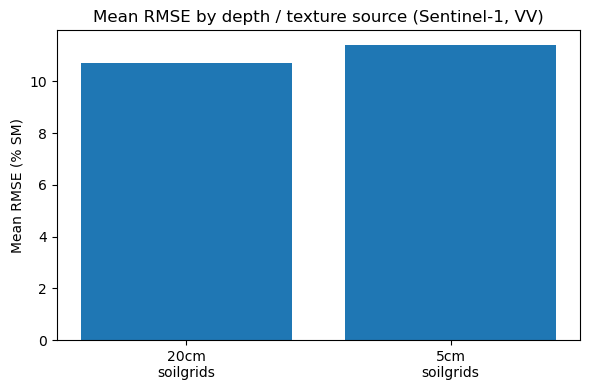

In [12]:
require_globals("summary_df")

import matplotlib.pyplot as plt

combo_labels = [f"{row.depth}\n{row.texture_source}" for row in summary_df.itertuples()]

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(combo_labels, summary_df["mean_rmse"])
ax.set_ylabel("Mean RMSE (% SM)")
ax.set_title("Mean RMSE by depth / texture source (Sentinel-1, VV)")
fig.tight_layout()
plt.show()


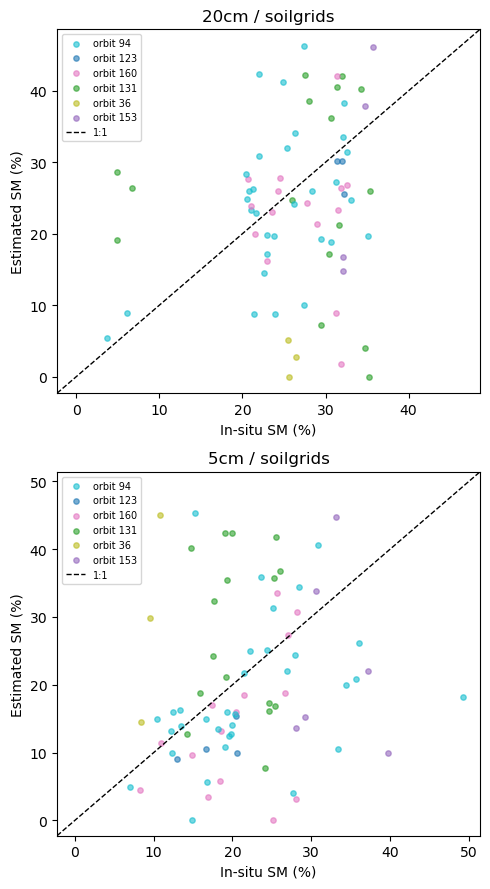

In [13]:
require_globals("results_raw", "results_df")

import matplotlib.cm as cm

depths = sorted(results_df["depth"].unique())
textures = sorted(results_df["texture_source"].unique())
all_orbits = sorted(results_df["orbit"].unique())
orbit_colors = dict(zip(all_orbits, cm.tab10(np.linspace(0, 1, max(len(all_orbits), 1)))))

fig, axes = plt.subplots(
    len(depths), len(textures), squeeze=False,
    figsize=(5 * len(textures), 4.5 * len(depths)),
)
for i, depth in enumerate(depths):
    for j, texture_source in enumerate(textures):
        ax = axes[i][j]
        for (station, orbit, tex, dep), (real_valid, est_valid) in results_raw.items():
            if tex != texture_source or dep != depth:
                continue
            ax.scatter(real_valid, est_valid, s=15, alpha=0.6, color=orbit_colors[orbit], label=f"orbit {orbit}")

        lo, hi = ax.get_xlim()
        lo2, hi2 = ax.get_ylim()
        lims = [min(lo, lo2), max(hi, hi2)]
        ax.plot(lims, lims, "k--", linewidth=1, label="1:1")
        ax.set_xlim(lims)
        ax.set_ylim(lims)
        ax.set_title(f"{depth} / {texture_source}")
        ax.set_xlabel("In-situ SM (%)")
        ax.set_ylabel("Estimated SM (%)")

        handles, labels = ax.get_legend_handles_labels()
        by_label = dict(zip(labels, handles))
        ax.legend(by_label.values(), by_label.keys(), fontsize=7)

fig.tight_layout()
plt.show()


## 11. Per-station timeseries

For a given (depth, texture_source) combination: one subplot per station,
plotting the in-situ SM series over its full recorded date range (not
clipped to that station's acquisition span, unlike an earlier version of
this notebook) against **one line per orbit** of estimated SM.
`plot_station_timeseries` is parameterized so any of the 2 (depth,
texture_source) combinations can be plotted -- called once below with a
representative default.

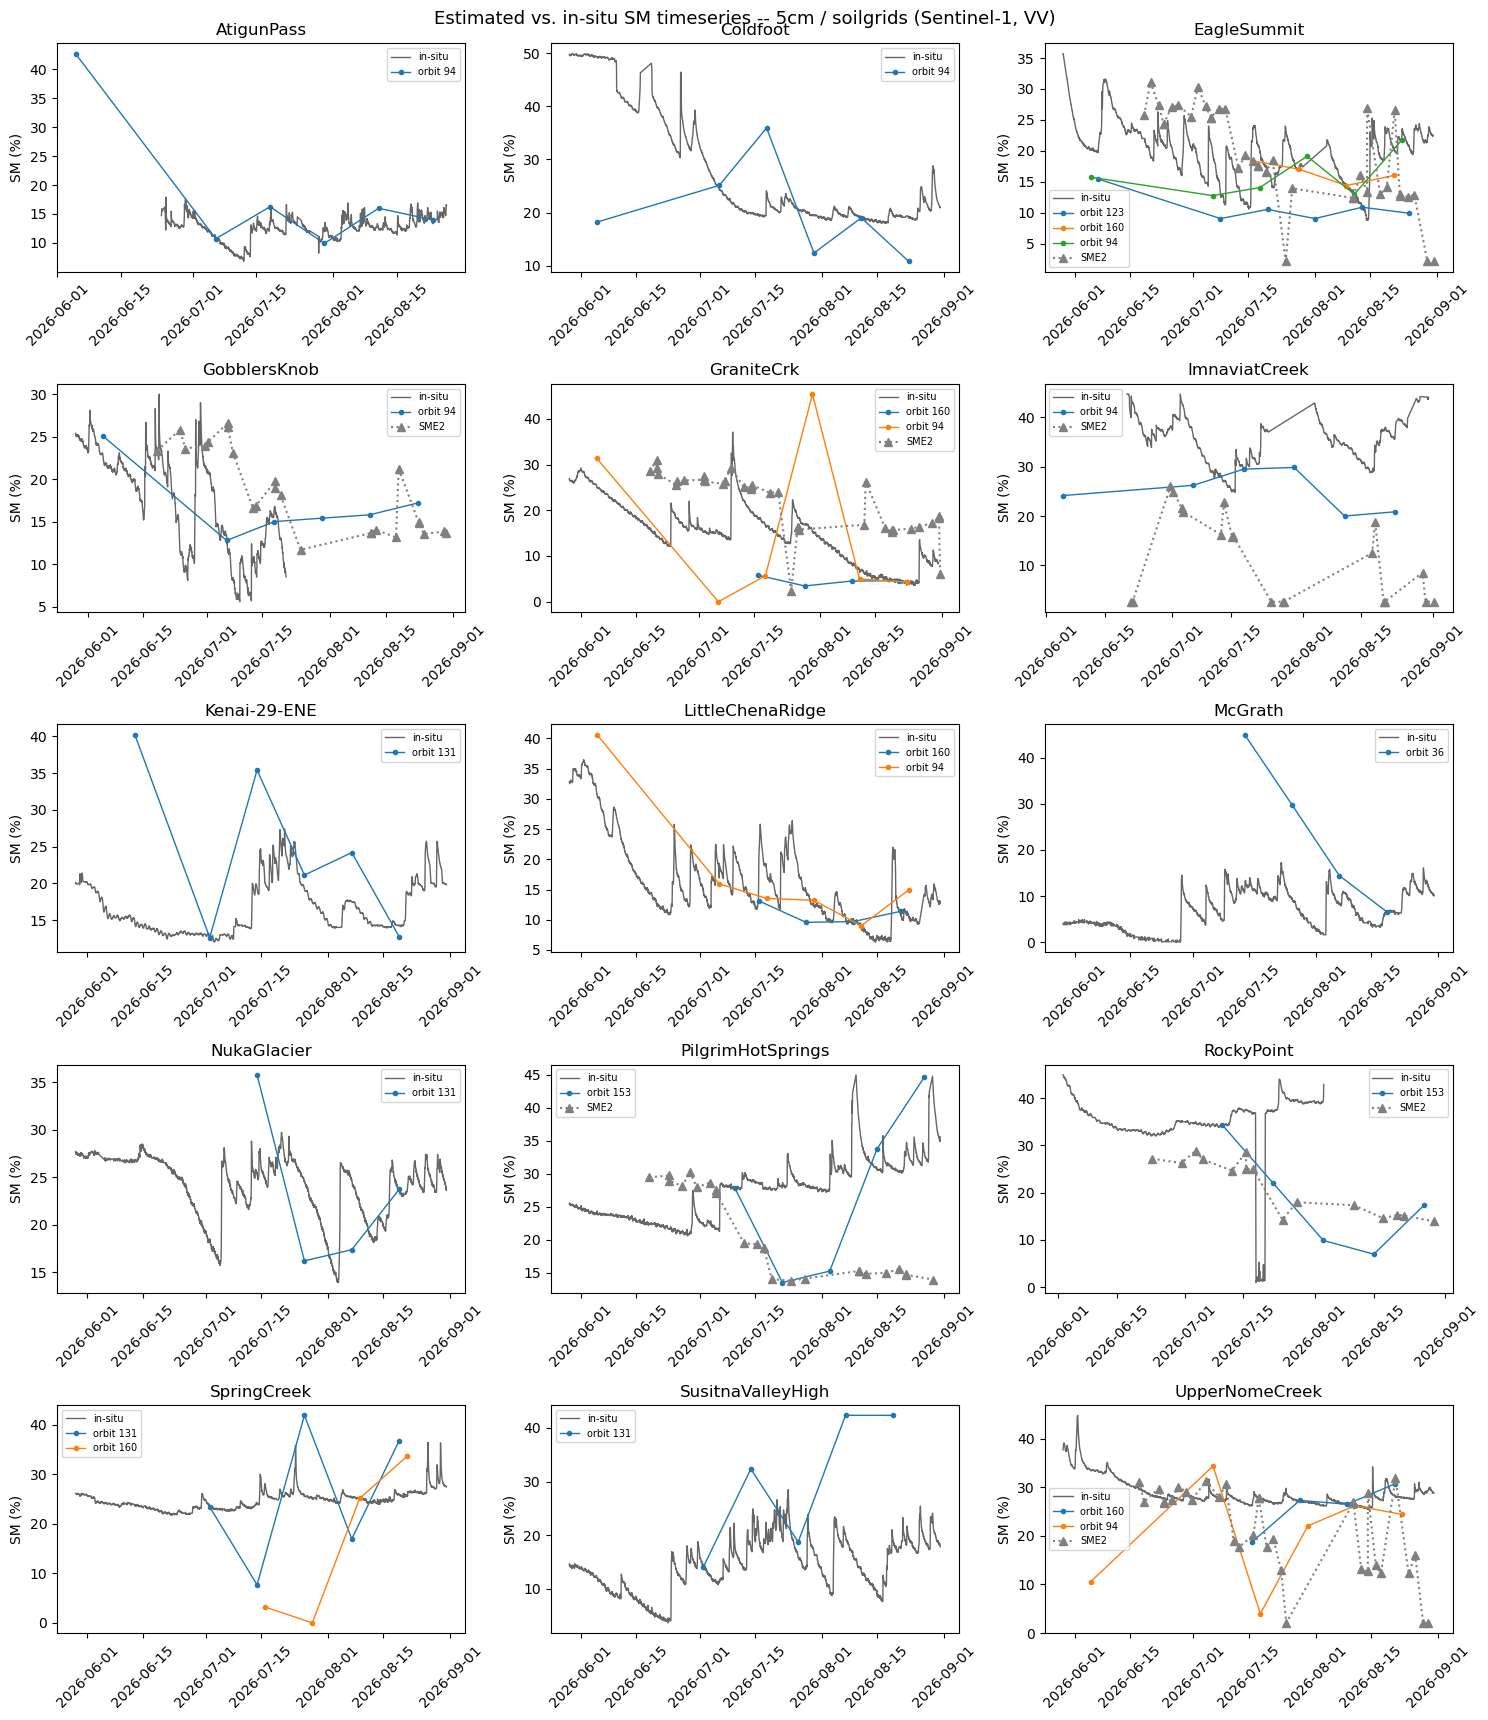

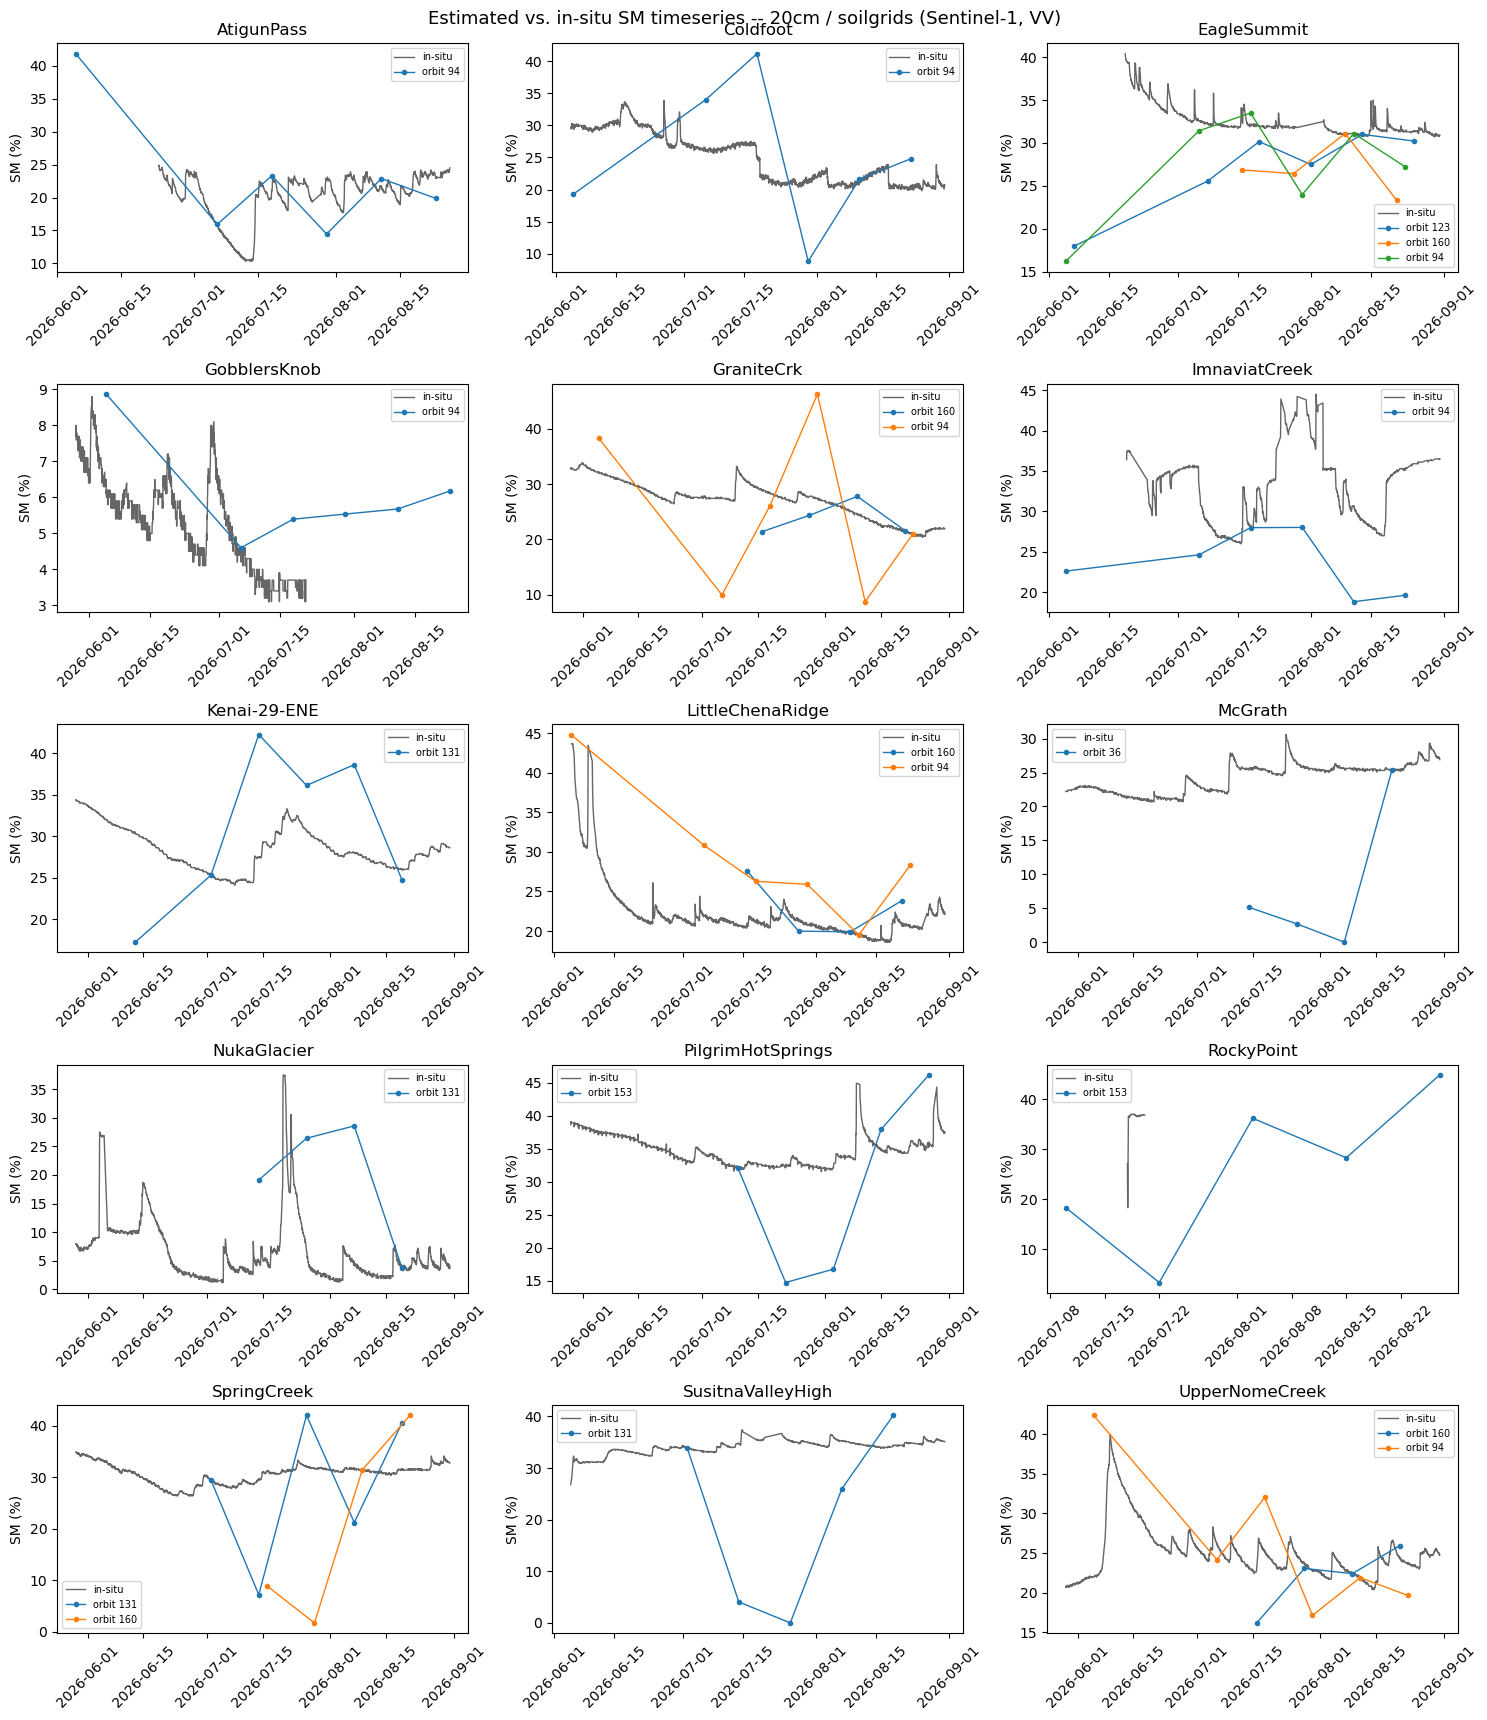

In [14]:
require_globals("sm_map", "slc_dates_group", "stations", "sme2_series_by_station")


def plot_station_timeseries(depth_label, texture_source):
    depth = DEPTH_BY_LABEL[depth_label]
    keys = [k for k in sm_map if k[2] == texture_source and k[3] == depth_label]
    # Skip stations with no in-situ ground truth at all (e.g. TurnagainPass) --
    # nothing to compare against, just clutters the grid with an empty line.
    station_list = sorted({k[0] for k in keys if read_insitu(k[0], depth) is not None})
    if not station_list:
        print(f"No results with in-situ ground truth for ({depth_label}, {texture_source})")
        return

    ncols = 3
    nrows = -(-len(station_list) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols * 5, nrows * 3.5), squeeze=False)
    axes = axes.flatten()

    for idx, station in enumerate(station_list):
        ax = axes[idx]
        station_orbits = sorted(k[1] for k in keys if k[0] == station)

        series = read_insitu(station, depth)
        if series is not None:
            ax.plot(series.index, series.values * 100, color="black", linewidth=1, alpha=0.6, label="in-situ")

        for orbit in station_orbits:
            key = (station, orbit, texture_source, depth_label)
            dates = slc_dates_group[(station, orbit)]
            sm_pix = sm_map[key]
            ax.plot(dates, sm_pix, marker="o", markersize=3, linewidth=1, label=f"orbit {orbit}")

        # SME2 is a single station-level reference series (no orbit/texture
        # dimensions) and only targets near-surface moisture, so only overlay
        # it on the 5cm panels.
        if depth_label == "5cm":
            sme2_series = sme2_series_by_station.get(station)
            if sme2_series is not None and not sme2_series.empty:
                ax.plot(sme2_series.index, sme2_series.values, "^:", color="gray", markersize=6, label="SME2")

        ax.set_title(station)
        ax.set_ylabel("SM (%)")
        ax.legend(fontsize=7)
        ax.tick_params(axis="x", rotation=45)

    for idx in range(len(station_list), len(axes)):
        axes[idx].axis("off")

    fig.suptitle(f"Estimated vs. in-situ SM timeseries -- {depth_label} / {texture_source} (Sentinel-1, VV)", fontsize=13)
    fig.tight_layout()
    plt.show()


plot_station_timeseries("5cm", "soilgrids")
plot_station_timeseries("20cm", "soilgrids")

<hr>

## Summary

`sm_map` holds the per-(station, orbit, texture_source, depth) SM estimate
array (VV only, no `pol` axis); `results_df` (Section 8) has the RMSE/bias/R
against in-situ SM for every combination, `results_raw` the underlying valid
(real, estimated) point pairs. Section 8b adds NISAR SME2 (`SME2_alaska.ipynb`'s
download, shared with `NISAR_SM_alaska.ipynb`) as an independent 5cm-only
reference product -- `sme2_series_by_station` and `sme2_results_df`, same
bit-0 "recommended" quality-flag correction documented there. `summary_df`
(Section 9) aggregates `results_df` by depth/texture_source and prints
SME2's own aggregate stats alongside it; Section 10 plots the RMSE bar chart
and faceted estimated-vs-in-situ scatter; Section 11 plots per-station SM
timeseries (one line per orbit, plus in-situ, plus a gray SME2 marker line
on the 5cm panels). Re-run after `S1_coherence_closure_alaska/` gains more
completed HyP3 pairs (re-run `S1_coh_phase_closure.ipynb`'s Sections 3-5),
`01_prepare_ismn_data.ipynb`/SoilGrids data changes, or `SME2_alaska.ipynb`
downloads more granules -- everything here is purely local, no network cost.

<hr>